# Figure 2: LPC demyelinating lesion, LPC10 S1 field of view

From the GEO RNA matrix and ATAC fragments and the CODEX scan to panels a-j of Fig. 2: AnnData, CODEX context, field of view,
Saturn targets, Saturn fit (seed 42), post-hoc tables and the panels.

**Dropped:** panels k-l (SEACells metacells vs isodepth, a comparison method; `lpc10_seacells_cis_benchmark.py` is not run).

**Result of the test run:** with the two pinned values (spot order, RNA GLM-PCs) the fit, tables and page a-g match the published ones exactly.
Without the pinned GLM-PCs the fit is a different optimum, and Fig. 2c depends on the draw (section 9).
**Inputs without a rerun:** CellCharter labels (section 3), GENCODE primary-chromosome GTF, CODEX channel list.

**Conda envs:** `spatialmultivelo` (this kernel), `tutorial_lpc` (scVI and CellCharter check), `catalign` (DBiT to CODEX registration).
**Time:** about 25 min for sections 1 to 8, plus about 15 min for the replicate in section 9, on a busy 128-core machine.

In [1]:
import sys; sys.path.insert(0, ".")
from pathlib import Path
import nbutil as nb
nb.init("fig2")
DS = "lpc10_fov"
STEPS = Path("steps").resolve()
FIGSTEPS = nb.PF / "fig2/steps"
SCRIPTS = {"PYTHONPATH": str(nb.HOLE / "scripts")}   # s02 looks for prep_real2 in the repo layout; here it sits in scripts/
TP = nb.ROOT / "claude_code_tutorial_lpc/results/timepoints"
CMP = f"python {STEPS}/fig2_compare_arrays.py"
(nb.HOLE / "results/atac_tiles").mkdir(parents=True, exist_ok=True)   # lpc10_fov_prep.py keeps a temporary file here

ok      mouse_atlas/mouse_aging/GSM9247593_07_LPC10S1_RNA_matrix.csv.gz  [raw, GEO GSM9247593 (LPC10 S1 RNA matrix)]
ok      mouse_atlas/mouse_aging/GSM9247593_07_LPC10S1_tissue_positions_list.csv.gz  [raw, GEO GSM9247593 spot positions]
ok      mouse_atlas/mouse_aging/GSM9249009_07_LPC10S1_atac_fragments.tsv.gz  [raw, GEO GSM9249009 (LPC10 S1 ATAC fragments)]
ok      mouse_atlas/encode_mouse.bed  [public, ENCODE mouse cCRE regions (mm10), peak set for the ATAC matrix]
ok      mouse_atlas/gencode.vM25.primary_chr.annotation.gtf  [public, GENCODE vM25 annotation restricted to primary chromosomes (the restricted file's producer was not found)]
ok      scdori_run/mouse_genome/mm10.fa  [public, UCSC mm10 genome]
ok      external_data/codex_lpc/Codex_LPC10_S1.qptiff  [raw, CODEX scan of the LPC10 S1 section]
ok      external_data/codex_lpc/channels_LPC10_S1.json  [CODEX channel order of the scan (panel metadata)]
ok      external_data/dbit_lpc10_spatial/GSM9247593_07_LPC10S1_tissue_hires_im

## 1. RNA and ATAC AnnData from GEO
RNA: in-tissue spots, genes in at least 10 spots. ATAC: fragments counted on the ENCODE cCREs (paired insertions), peaks in at
least 1% of barcodes; spots present in both. Recovered from `mouse_atlas/process.py`.

**Pinned value:** that script took the spot order from a Python `set`, which differs in every process. Spot order changes the fit,
so the published order comes from `steps/fig2_lpc10s1_obs_order.txt`. About 3 min.

In [2]:
nb.step("arcseq_from_geo", f"python {STEPS}/fig2_arcseq_lpc10.py", [TP / "arcseq_LPC10S1_rna_adata.h5ad", TP / "arcseq_LPC10S1_atac_adata.h5ad"])
nb.step("compare_arcseq", f"python {STEPS}/fig2_compare_arcseq.py")
print(open(nb.HOLE / "logs/compare_arcseq.log").read()[-900:])

[skip] arcseq_from_geo: outputs exist
[run ] compare_arcseq: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_arcseq.py


[done] compare_arcseq: 0.1 min


rna: shape (8180, 15799) vs (8180, 15799); obs order same True; var same True; X differing entries 0; spatial max diff 0
atac: shape (8180, 68021) vs (8180, 68021); obs order same True; var same True; X differing entries 0; spatial max diff 0



## 2. CODEX context (Fig. 2a)
Normalised channels at pyramid level 3, CD11c+ foci in white matter and the box around the two largest (context only). The spots
Saturn is fitted on are chosen on the DBiT data in section 4. Under 1 min.

In [3]:
CX = nb.ROOT / "external_data/codex_lpc"
nb.step("s00_codex_overview", f"python {FIGSTEPS}/s00_codex_overview.py", [CX / "overview_LPC10_S1_lvl3.npz"])
nb.step("s01_codex_fov", f"python {FIGSTEPS}/s01_codex_hotspots_fov.py", [CX / "cd11c_hotspots_lvl3.json", CX / "fov_lesion_plus_SM.json"])
nb.step("compare_codex", f"{CMP} external_data/codex_lpc/overview_LPC10_S1_lvl3.npz external_data/codex_lpc/cd11c_hotspots_lvl3.json external_data/codex_lpc/fov_lesion_plus_SM.json")
print(open(nb.HOLE / "logs/compare_codex.log").read()[-700:])

[skip] s00_codex_overview: outputs exist
[skip] s01_codex_fov: outputs exist
[run ] compare_codex: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_arrays.py external_data/codex_lpc/overview_LPC10_S1_lvl3.npz external_data/codex_lpc/cd11c_hotspots_lvl3.json external_data/codex_lpc/fov_lesion_plus_SM.json


[done] compare_codex: 0.0 min


external_data/codex_lpc/overview_LPC10_S1_lvl3.npz keys same
  (arrays not listed are exactly equal)
external_data/codex_lpc/cd11c_hotspots_lvl3.json identical
external_data/codex_lpc/fov_lesion_plus_SM.json identical



## 3. CellCharter labels (input, with a rerun for comparison)
The field of view excludes the cortex clusters (K = 10: 1, 5, 2) of `LPC10_cc_labels.csv`. The producer
(`lpc_timepoint_cellcharter.py`, GPU) does not seed scVI and the three ids were picked by eye, so the labels stay an input. This step
reruns the producer on LPC10 alone and reports the agreement; its labels are not used below. About 1 min on GPU, `tutorial_lpc`.

In [4]:
CC = "results/real_saturn/lpc10_cellcharter_rerun"
nb.step("cellcharter_check", f"python {STEPS}/fig2_cellcharter_check.py", [f"{CC}/rerun_vs_published.csv"], env="tutorial_lpc")
print(open(nb.RES / "lpc10_cellcharter_rerun/rerun_vs_published.csv").read())

[skip] cellcharter_check: outputs exist
K,ARI,identical,cortex_mask_agreement_K10
3,0.7536278114692531,False,0.9342298288508557
5,0.5769669877626512,False,0.9342298288508557
7,0.7242174895803689,False,0.9342298288508557
10,0.6961375666401156,False,0.9342298288508557



## 4. Field of view and Saturn targets
Microglia score hotspots on the DBiT section give the lesion and the distal white-matter focus; their padded bounding box minus
the cortex clusters is the field of view (3,425 spots). RNA target: GLM-PCA over the HVGs of these spots. ATAC target: 5 kb tile
spectral embedding, component 1 dropped. About 4 min.

**Pinned value:** `glmpca` starts from an unseeded `np.random` draw, so each run gives different RNA factors, and the fit follows
them. The published `Y_RNA` is stored in `steps/fig2_glmpc_published.npz` and put back by `steps/fig2_pin_glmpc.py`, so the rest of the
notebook can be checked against the published results. Section 9 shows what a fresh draw gives.

In [5]:
nb.step("s02_hotspots", f"python {FIGSTEPS}/s02_lpc10_hotspots.py", ["results/real_saturn/lpc10_hotspots.npz"], extra_env=SCRIPTS)
nb.step("s03_fov", f"python {FIGSTEPS}/s03_lpc10_fov_select.py", ["results/real_saturn/lpc10_fov.npz", "results/real_saturn/lpc10_fov.json"], extra_env=SCRIPTS)
nb.step("prep_targets", "python scripts/lpc10_fov_prep.py", [f"results/real_saturn/targets_{DS}.npz"])
nb.step("pin_glmpc", f"python {STEPS}/fig2_pin_glmpc.py", ["results/real_saturn/fig2_glmpc_pinned.txt"])
print(open(nb.HOLE / "logs/pin_glmpc.log").read())
R0 = "Hole/gaston_mix_mm/results/real_saturn"
nb.step("compare_targets", f"{CMP} {R0}/lpc10_hotspots.npz {R0}/lpc10_fov.npz {R0}/lpc10_fov.json {R0}/targets_{DS}.npz")
print(open(nb.HOLE / "logs/compare_targets.log").read()[-1500:])

[skip] s02_hotspots: outputs exist
[skip] s03_fov: outputs exist
[skip] prep_targets: outputs exist
[skip] pin_glmpc: outputs exist
Y_RNA replaced by the published GLM-PCs (fresh draw differed by up to 9.914)

[run ] compare_targets: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_arrays.py Hole/gaston_mix_mm/results/real_saturn/lpc10_hotspots.npz Hole/gaston_mix_mm/results/real_saturn/lpc10_fov.npz Hole/gaston_mix_mm/results/real_saturn/lpc10_fov.json Hole/gaston_mix_mm/results/real_saturn/targets_lpc10_fov.npz


[done] compare_targets: 0.0 min


Hole/gaston_mix_mm/results/real_saturn/lpc10_hotspots.npz keys same
  (arrays not listed are exactly equal)
Hole/gaston_mix_mm/results/real_saturn/lpc10_fov.npz keys same
  (arrays not listed are exactly equal)
Hole/gaston_mix_mm/results/real_saturn/lpc10_fov.json identical
Hole/gaston_mix_mm/results/real_saturn/targets_lpc10_fov.npz keys same
  (arrays not listed are exactly equal)



## 5. Saturn fit
Seed 42 on CPU with `SAT_THREADS=8 OMP_NUM_THREADS=8`, the published settings. Thread count changes the fit (4 threads: r = 0.86 on
RNA, r = 0.95 on ATAC). About 6 min.

In [6]:
nb.step("fit", f"python scripts/run_real2.py --dataset {DS} --seeds 1 --seed0 42", [f"results/real_saturn/{DS}/axes.csv"], threads=8, omp=8, device="cpu")
nb.compare_axes(DS)

[skip] fit: outputs exist
  dataset   axis  max_abs_diff  abs_r
lpc10_fov  d_RNA           0.0    1.0
lpc10_fov d_ATAC           0.0    1.0


,dataset,axis,max_abs_diff,abs_r
0,lpc10_fov,d_RNA,0.0,1.0
1,lpc10_fov,d_ATAC,0.0,1.0


## 6. Post-hoc tables
Run with `OMP_NUM_THREADS` unset, as published: BLAS thread count flips exact ties. Domain K per axis is read from
`domain_k_elbow/k_elbow.json` (RNA 3, ATAC 2). About 6 min, most of it the marker screens.

In [7]:
R = "results/real_saturn"
nb.step("domain_annot", "python scripts/lpc10_fov_domain_annot.py", [f"{R}/{DS}_domains/domain_annotation.csv"])
nb.step("marker_functions", f"python scripts/marker_function_panels.py {DS} 8 8", [f"{R}/{DS}_marker_functions/gene_screen.csv", f"{R}/{DS}_marker_functions/peak_screen.csv"], extra_env={"RESCREEN": "1"})
nb.step("tf_activity_rho", f"python scripts/saturn_tf_activity_rho.py {DS}", [f"{R}/{DS}_tf_activity/tf_bins.csv", f"{R}/{DS}_tf_activity/tf_fits.csv"])
nb.step("tf_activity_spatial", f"python scripts/saturn_tf_activity_spatial.py {DS}", [f"{R}/{DS}_tf_activity/tf_z_per_spot.npz"])
nb.step("cis_pairs", f"python scripts/saturn_cis_function_pairs.py {DS} 1500", [f"{R}/{DS}_cis_pairs/cis_function_pairs.csv"])
nb.step("cis_gradient", f"python scripts/saturn_cis_gradient_decomp.py {DS} 1500", [f"{R}/{DS}_cis_pairs/cis_gradient_decomp.csv"])
nb.step("posthoc", "python scripts/lpc10_fov_posthoc.py", [f"{R}/{DS}_posthoc/infl_gene_axis_fits.csv"])
for t in ("domains/domain_annotation.csv", "marker_functions/gene_screen.csv", "marker_functions/peak_screen.csv", "tf_activity/tf_bins.csv", "tf_activity/tf_fits.csv",
          "cis_pairs/cis_function_pairs.csv", "cis_pairs/cis_gradient_decomp.csv", "posthoc/infl_gene_axis_fits.csv"):
    nb.compare_table(f"{DS}_{t}", tol=1e-6)
nb.step("compare_tf_z", f"{CMP} {R0}/{DS}_tf_activity/tf_z_per_spot.npz {R0}/{DS}/summary.json")
print(open(nb.HOLE / "logs/compare_tf_z.log").read()[-700:])
# summary.json: the figure reads only R2_whole, which agrees to within 1e-7. axis_axis_corr and axis_depth_corr are written differently by the current
# run_real2.py than in the published file (published +0.08, here -0.08; the Spearman r of the published axes is -0.08).

[skip] domain_annot: outputs exist
[skip] marker_functions: outputs exist
[skip] tf_activity_rho: outputs exist
[skip] tf_activity_spatial: outputs exist
[skip] cis_pairs: outputs exist
[skip] cis_gradient: outputs exist
[skip] posthoc: outputs exist
lpc10_fov_domains/domain_annotation.csv: shape (8, 16) vs (8, 16); max numeric diff 0; MATCH
lpc10_fov_marker_functions/gene_screen.csv: shape (1500, 5) vs (1500, 5); max numeric diff 0; MATCH
lpc10_fov_marker_functions/peak_screen.csv: shape (6000, 8) vs (6000, 8); max numeric diff 0; MATCH
lpc10_fov_tf_activity/tf_bins.csv: shape (2760, 8) vs (2760, 8); max numeric diff 0; MATCH
lpc10_fov_tf_activity/tf_fits.csv: shape (46, 8) vs (46, 8); max numeric diff 0; MATCH


lpc10_fov_cis_pairs/cis_function_pairs.csv: shape (175210, 15) vs (175210, 15); max numeric diff 0; MATCH
lpc10_fov_cis_pairs/cis_gradient_decomp.csv: shape (164530, 8) vs (164530, 8); max numeric diff 0; MATCH
lpc10_fov_posthoc/infl_gene_axis_fits.csv: shape (37, 11) vs (37, 11); max numeric diff 0; MATCH
[run ] compare_tf_z: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_arrays.py Hole/gaston_mix_mm/results/real_saturn/lpc10_fov_tf_activity/tf_z_per_spot.npz Hole/gaston_mix_mm/results/real_saturn/lpc10_fov/summary.json


[done] compare_tf_z: 0.0 min


Hole/gaston_mix_mm/results/real_saturn/lpc10_fov_tf_activity/tf_z_per_spot.npz keys same
  (arrays not listed are exactly equal)
Hole/gaston_mix_mm/results/real_saturn/lpc10_fov/summary.json DIFFERS in ['R2_whole', 'axis_axis_corr', 'axis_depth_corr']



## 7. DBiT spots on CODEX (Fig. 2a)
Catalign (env `catalign`, package at `catalign_src`) registers the DBiT chip on CODEX through white-matter images. Scripts
01, 02 and 03 of `catalign_lpc10/scripts` are unchanged; the last step keeps the coordinate part of script 05. `n_jobs` 30 (published run: 32). About 2 min.

In [8]:
CAT = nb.ROOT / "catalign_lpc10"; I = CAT / "inputs"; W = CAT / "results/LPC10S1_wm"
EX = {"PYTHONWARNINGS": "ignore"}
nb.step("catalign_inputs", f"python {STEPS}/fig2_catalign_prep_inputs.py", [I / "codex_lvl1_tissue.tif"], env="catalign")
nb.step("catalign_features", f"python {STEPS}/fig2_catalign_feature_images.py", [I / "codex_lvl1_feat.tif"], env="catalign")
nb.step("catalign_wm", f"python {STEPS}/fig2_catalign_wm_feature_images.py", [I / "codex_lvl1_wm.tif", I / "dbit_chip_wm.png"], env="catalign")
nb.step("catalign_config", f"python {STEPS}/fig2_catalign_spots.py config", [CAT / "config_wm.yaml"], env="catalign")
cat_bin = Path(nb.env_python("catalign")).parent / "Catalign"
nb.step("catalign_run", f"{cat_bin} run config_wm.yaml --n-jobs 30", [W / "registration.json"], cwd=CAT, extra_env=EX)
nb.step("catalign_spots", f"python {STEPS}/fig2_catalign_spots.py spots", [W / "LPC10S1_spots_in_codex.csv"], env="catalign")
nb.step("compare_catalign", f"python {STEPS}/fig2_compare_catalign.py")
print(open(nb.HOLE / "logs/compare_catalign.log").read()[-400:])

[skip] catalign_inputs: outputs exist
[skip] catalign_features: outputs exist
[skip] catalign_wm: outputs exist
[skip] catalign_config: outputs exist
[skip] catalign_run: outputs exist
[skip] catalign_spots: outputs exist
[run ] compare_catalign: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_catalign.py


[done] compare_catalign: 0.0 min


spots 9216; displacement vs published px: median 0, max 0



## 8. Figure, panels a-j
The figure's builders, unmodified, through `steps/fig2_saturn_panels.py`. Part 1 (a-g) has the published layout; part 2 keeps h-j.

[run ] figure: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_saturn_panels.py


[done] figure: 0.3 min


[run ] compare_figure: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig2_compare_figure.py fig2_part1


[done] compare_figure: 0.0 min


fig2_part1: size (5603, 4271, 3), pixels differing 0 of 23930413, max channel diff 0



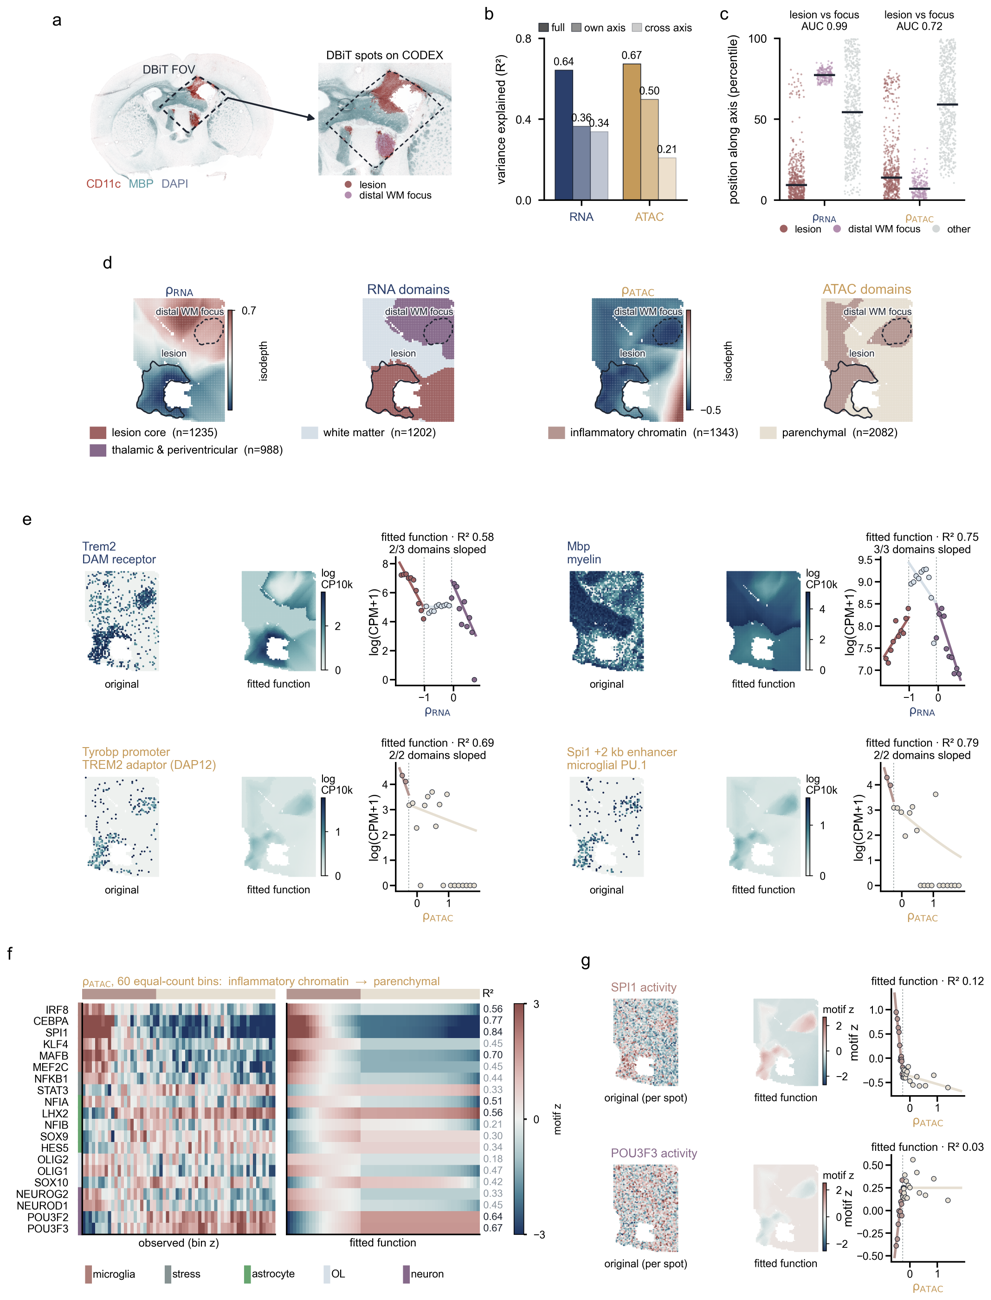

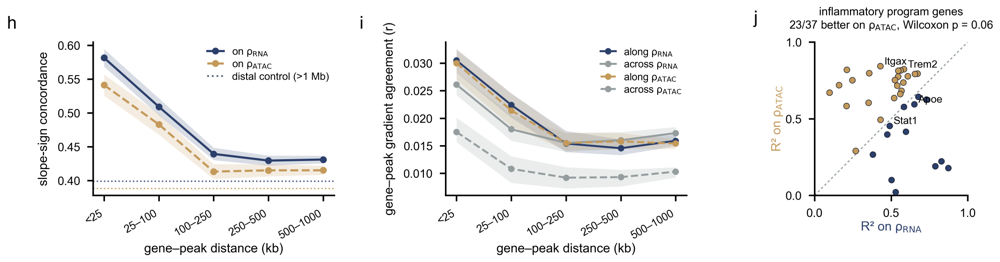

In [9]:
nb.step("figure", f"python {STEPS}/fig2_saturn_panels.py")
nb.step("compare_figure", f"python {STEPS}/fig2_compare_figure.py fig2_part1")
print(open(nb.HOLE / "logs/compare_figure.log").read()[-300:])
from PIL import Image as PI
from IPython.display import display
PI.MAX_IMAGE_PIXELS = None
for n in ("fig2_part1", "fig2_part2"):                    # small previews; full size in published_figures/fig2/
    im = PI.open(nb.PF / f"fig2/{n}.png").convert("RGB"); im.thumbnail((1000, 1300)); display(im)

## 9. Replicate with a fresh GLM-PCA draw
The chain of sections 4 to 6 in its own workspace (`fresh_glmpc/`) without the published GLM-PCs. This is what a reader gets from
the raw data alone. The printed values come from the figure's own panel functions (`steps/fig2_claims.py`). About 15 min.
Each run is a new draw, so these numbers change between runs. An earlier draw gave rho_RNA lesion / focus median percentiles of 8 / 22
(published 9 / 77), AUC 0.91, and |r| = 0.28 with the published axes on both rho_RNA and rho_ATAC.

In [10]:
import json
nb.step("claims", f"python {STEPS}/fig2_claims.py", [f"{R}/fig2_claims.json"])
FR = nb.ROOT / "fresh_glmpc/Hole/gaston_mix_mm/results/real_saturn/fresh_replicate.json"
nb.step("fresh_replicate", f"python {STEPS}/fig2_fresh_replicate.py", [FR])
F = json.load(open(FR)); print(json.dumps(F["axes"])); print("metric: pinned | fresh")
for k in ("R2_whole", "axis_corr", "c_auc", "c_median_percentile", "h", "i", "j", "e_Trem2_R2", "e_Mbp_R2"):
    print(k, json.dumps(F["pinned"][k]), "|", json.dumps(F["fresh"][k]))

[skip] claims: outputs exist
[skip] fresh_replicate: outputs exist
[{"dataset": "lpc10_fov", "axis": "d_RNA", "max_abs_diff": 3.0198514461517334, "abs_r": 0.9803947758695312}, {"dataset": "lpc10_fov", "axis": "d_ATAC", "max_abs_diff": 0.796754717826843, "abs_r": 0.9352828714291918}]
metric: pinned | fresh
R2_whole {"RNA": {"full": 0.6429, "own_axis_only": 0.3647, "other_axes_only": 0.338}, "ATAC": {"full": 0.6738, "own_axis_only": 0.498, "other_axes_only": 0.2091}} | {"RNA": {"full": 0.6362, "own_axis_only": 0.3469, "other_axes_only": 0.3361}, "ATAC": {"full": 0.6759, "own_axis_only": 0.4934, "other_axes_only": 0.1782}}
axis_corr -0.08 | -0.06
c_auc {"RNA": [0.9947, 0.0], "ATAC": [0.7228, 0.0]} | {"RNA": [0.9845, 0.0], "ATAC": [0.6491, 0.0]}
c_median_percentile {"('RNA', 'lesion')": 9.2847, "('RNA', 'distal WM focus')": 77.3869, "('RNA', 'other')": 54.3066, "('ATAC', 'lesion')": 13.8978, "('ATAC', 'distal WM focus')": 6.9051, "('ATAC', 'other')": 59.0657} | {"('RNA', 'lesion')": 10.175